<a href="https://colab.research.google.com/github/hkim9712/MPM_200_Kim/blob/main/notebooks/MPM200_Lab3_hummers_survive_HK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/EpiPandit/MPM_200/blob/main/Session%205/Assignment%201%20-%20Will%20the%20Hummers%20Survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐦 MPM 200 · Week 1 Assignment: *Will the Hummers Survive?*

**Due:** Wednesday 28 October 2026, 9:00 AM · **Total:** 50 points + 5 bonus

**Ground rules**
* Show your work: code **and** output. It lets us follow your thinking and give partial credit.
* Work together, but don't copy. Read each other's code until you could have written it yourself.
* Cells with blanks (`____`) won't run until you fill them in. That's on purpose.

## 📟 Mission briefing

You're the wildlife veterinarian on call for three California wildlife rehabilitation centers. Every year, hummingbirds arrive in shoeboxes and teacups: stunned by windows, carried in by cats, fallen from nests. Some go on to fly again; many don't.

The centers have pooled **more than 25 years of intake records (1991–2016)**. Your mission is to find out **which birds make it back to the sky, and what tips the odds.**

### 🗂️ Case file: data dictionary

| Column | What it records |
|---|---|
| `Admitted` | Date the bird arrived at the center |
| `Disposition_binary` | Outcome: **Died** or **Released** |
| `Place` | Rehabilitation center |
| `F_Aid` | Did the finder give first aid? (Yes/No) |
| `Species_e` | `ANHU` = Anna's Hummingbird · `BCHU` = Black-chinned Hummingbird · `Selasphorus` = orange *Selasphorus* species (e.g., Allen's, Rufous) not identified to species · `Non-selasphorus` = green birds not identified to species |
| `Sex_e`, `Age_e` | Sex and age class as recorded |
| `Brought_in_after` | Days the finder kept the bird before bringing it in |
| `season` | Season of admission |
| `r` | Reason for admission |
| `Green_Orange` | Broad group: green (non-*Selasphorus*) or orange (*Selasphorus*) |
| `ID` | Unique ID for each bird |

## 🍄 Case file 0 · Warm-up: make some noise (2 pts)

**Q0.** Install **beepr** and play the **Mario** sound. Then have a cowsay animal welcome you to the mission (use your name!).

> **Why the helper below?** `beep()` plays sound on the computer *running R*. On Colab that's a Google server with no speakers, so you'd hear nothing. The helper sends the very same sound file to **your browser** instead. On your own laptop, plain `beep("mario")` works.

In [ ]:
install.packages(c("beepr", "cowsay"))
library(beepr)
library(cowsay)

# Plays a beepr sound in your browser (for Colab)
beep_colab <- function(sound = "smb_stage_clear") {     # smb_stage_clear = the Mario sound
  wav <- list.files(system.file("sounds", package = "beepr"),
                    pattern = sound, full.names = TRUE)[1]
  b64 <- jsonlite::base64_enc(readBin(wav, "raw", file.info(wav)$size))
  IRdisplay::display_html(sprintf('<audio controls autoplay src="data:audio/wav;base64,%s"></audio>', b64))
}

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
beep("mario")

Warning message in value[[3L]](cond):
“beep() could not play the sound due to the following error:
Error in play.default(x, rate, ...): no audio drivers are available
”


In [ ]:
beep_colab()     # press ▶ if your browser blocks autoplay

say("Welcome to Hummingbird HQ, Dr. Kim!", by = "pumpkin", by_color = "orange")


 _____________________________________ 
< Welcome to Hummingbird HQ, Dr. Kim! >
 ------------------------------------- 
               \
                \

                  ___
               ___)__|_
          .-*'          '*-,
         /      /|   |\     \
        ;      /_|   |_\     ;
        ;   |\           /|  ;
        ;   | ''--...--'' |  ;
         \  ''---.....--''  /
          ''*-.,_______,.-*'  [nosig]

In [ ]:
library(dplyr)
library(ggplot2)
options(repr.plot.width = 7, repr.plot.height = 4.5)
dir.create("outputs", showWarnings = FALSE)

## 📋 Case file 1 · Intake: read the records

**Q1 (2 pts).** Read `Hummingbird_data.csv` into an object called `data`. It lives on the course GitHub, so you can read it straight from the URL.

In [ ]:
dir.create("data_raw", showWarnings = FALSE)
dir.create("outputs",  showWarnings = FALSE)
list.files()

[1] "data_raw"    "outputs"     "sample_data"

In [ ]:
#url <- "https://raw.githubusercontent.com/EpiPandit/MPM_200/main/data/Hummingbird_data.csv"
data <- read.csv("/content/data_raw/Hummingbird_data.csv")
colnames(data)

[1] "Admitted"           "Disposition_binary" "Place"             
 [4] "F_Aid"              "Species_e"          "Sex_e"             
 [7] "Age_e"              "Brought_in_after"   "season"            
[10] "r"                  "Green_Orange"       "ID"

**Q2 (1 pt).** 🔮 *Predict first:* 26 years, three centers. Guess how many birds: `5500`.
Now find how many rows and columns `data` has.

In [ ]:
dim(data)
nrow(data)
ncol(data)

[1] 6908   12

[1] 6908

[1] 12

**Q3 (3 pts).** Check the structure of the data.
* Use `str()` to see each column.
* Use `sapply()` with `class` to list every column's data type.
* Which columns are text (`character`) and which are numbers? Is `Admitted` stored as a date? Note anything that looks odd.

In [ ]:
str(data)

data_types <- sapply(data, class)
print(data_types)

'data.frame':	6908 obs. of  12 variables:
 $ Admitted          : chr  "1/2/1991" "1/2/1991" "1/4/1991" "1/5/1991" ...
 $ Disposition_binary: chr  "Died" "Released" "Died" "Died" ...
 $ Place             : chr  "Lindsey" "Lindsey" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "Yes" "No" "No" ...
 $ Species_e         : chr  "ANHU" "ANHU" "ANHU" "ANHU" ...
 $ Sex_e             : chr  "Female-like " "Female-like " "Female-like " "Female-like " ...
 $ Age_e             : chr  "adult-like" "adult-like" "adult-like" "adult-like" ...
 $ Brought_in_after  : int  1 0 0 4 0 0 0 0 0 0 ...
 $ season            : chr  "Winter" "Winter" "Winter" "Winter" ...
 $ r                 : chr  "found on the ground" "unknown" "suspect torpor-like state" "unknown" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "1_ANHU" "2_ANHU" "3_ANHU" "4_ANHU" ...
          Admitted Disposition_binary      

✍️ **Your answer:** Only 'Brought_in_after' is number column and others are text columns. However, admitted supposed be a number as it is a date.

### 🎲 Draw your own reproducible sample
Each of you will analyse a random sample of 5,000 birds. `set.seed()` makes "random" **repeatable**: the same seed always gives the same sample, so your instructor can reproduce your results exactly (remember the reproducibility checklist from lecture?).

👉 Replace `1225` with **your birthday as MMDD** (e.g., 3 July → `0703`, which R reads as 703).

In [ ]:
set.seed(0102)                              # ← your birthday, MMDD
model_data <- slice_sample(data, n = 5000)

**Use `model_data` for the rest of the assignment.**

**Q4 (1 pt).** How many rows and columns does `model_data` have?

In [ ]:
dim(model_data)
ncol(model_data)
nrow(model_data)

[1] 5000   12

[1] 12

[1] 5000

**Q5 (2 pts).** How many columns are **categorical** and how many are **continuous**? Name the continuous one(s). Is `ID` a useful variable for analysis?

In [ ]:
str(model_data)
data_types <- sapply(model_data, class)
print(data_types)

'data.frame':	5000 obs. of  12 variables:
 $ Admitted          : chr  "4/14/2013" "4/10/2002" "3/27/2004" "4/8/2013" ...
 $ Disposition_binary: chr  "Died" "Died" "Died" "Died" ...
 $ Place             : chr  "Lindsey" "Lindsey" "Lindsey" "malibu" ...
 $ F_Aid             : chr  "No" "Yes" "No" "No" ...
 $ Species_e         : chr  "ANHU" "ANHU" "ANHU" "Selasphorus" ...
 $ Sex_e             : chr  "Female-like " "Female-like " "Female-like " "Female-like " ...
 $ Age_e             : chr  "adult-like" "adult-like" "adult-like" "adult-like" ...
 $ Brought_in_after  : int  0 1 0 0 1 22 0 0 0 0 ...
 $ season            : chr  "Spring" "Spring" "Spring" "Spring" ...
 $ r                 : chr  "found on the ground" "found on the ground" "window hit" "unknown" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Selasphorus spp." ...
 $ ID                : chr  "4695_ANHU" "2209_ANHU" "2644_ANHU" "5770_ALHU" ...
          Admitted Disposition_b

✍️ **Your answer:**
* Number of categorical column: 10
* Numer of continuous column: 2
* Is ID a useful variable? It is not useful for analysis but more to identify individual bird.

**Q6 (2 pts).** Save your sample as `Hummingbird_data_YOURNAME.csv` in the `outputs` folder, and submit it. Use `row.names = FALSE`.

In [ ]:
write.csv(model_data, "outputs/Hummingbird_data_Hayoung.csv", row.names = FALSE)

## 🏥 Case file 2 · Which hospital is busiest?

Let's count how many birds each center admitted (column `Place`), using dplyr to build a summary table and ggplot2 to plot it.

In [ ]:
rehab <- model_data %>%
  group_by(Place) %>%
  summarise(count = n_distinct(ID))
rehab

Place,count
<chr>,<int>
Lindsey,4148
Santa Barbara,73
malibu,779


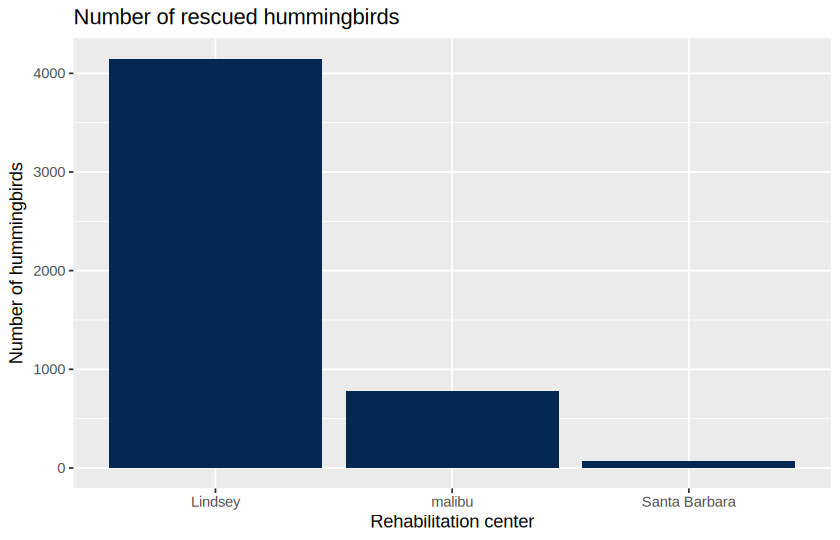

In [ ]:
p <- ggplot(rehab, aes(x = Place, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Rehabilitation center") +
  ylab("Number of hummingbirds") +
  labs(title = "Number of rescued hummingbirds")
p

**Q7 (2 pts).** Save this plot as a **PDF, 4 inches wide and 3 inches tall**, and submit it.

In [ ]:
ggsave("outputs/rehab_counts_Hayoung.pdf", p, width = 4, height = 3)

**Q8 (3 pts).** Explain the code in words, line by line, from the line that creates `rehab` through the plot. What does each function do?

✍️ **Your answer:**
* p<-: assign the plot that we are creating
* ggplot(rehab, : we are creating plot using 'rehab' data
* aes(x = Place, y = count): set the data that we would like to put in x-axis and y-axis.
* geom_col(fill = "#022851"): create columns (bar chart) and color with "022851" color.
* xlab("Rehabilitation center"): label the x-axis with "Rehabiliation center"
* ylab("Number of hummingbirds"): label the y-axis with "Number of hummingbirds"
* labs(title = "Number of rescued hummingbirds"): make a title of the plot as "Number of rescued hummingbirds"
* p: diplays the final plot

**Q9 (2 pts).** 🤔 Lindsey admitted far more birds than the other centers. Does that mean more birds **die** at Lindsey? Why are raw counts not enough to compare outcomes between centers?

✍️ **Your answer:**
Raw counts are not enough to compare outcomes between centers as we have different population to compare the death. By looking at just raw counts of the death, Lindsey center has the most but it is also because they admitted significant more numers of birds compare to others.

## 🔬 Case file 3 · Who survives?

**Q10 (6 pts).** Pick **three** variables you think could affect survival (e.g., `F_Aid`, `Age_e`, `r`, `season`, `Sex_e`, `Species_e`).
For **each** variable:
1. Make a table counting unique birds (`ID`) for every combination of the variable and `Disposition_binary`.
2. Plot it as bars, split into panels with `facet_grid()`.

Copy the two cells below for each variable.

In [ ]:
# F_Aid: Did the finder give first aid? (Yes/No)
df <- model_data %>%
  group_by(F_Aid, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df

F_Aid,Disposition_binary,count
<chr>,<chr>,<int>
No,Died,2134
No,Released,1163
Yes,Died,1097
Yes,Released,606


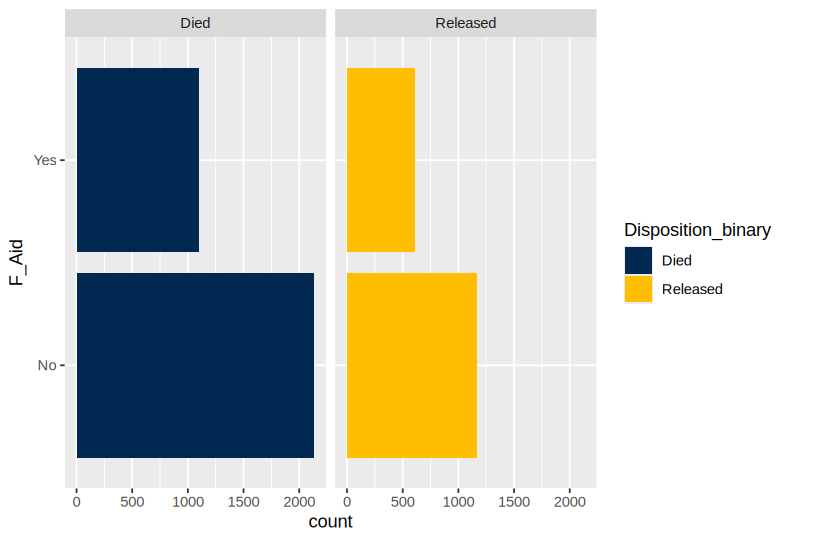

In [ ]:
ggplot(df, aes(x = F_Aid, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

In [ ]:
# Age_e: age class as recorded
df <- model_data %>%
  group_by(Age_e, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df

Age_e,Disposition_binary,count
<chr>,<chr>,<int>
Nestling,Died,414
Nestling,Released,747
adult-like,Died,2817
adult-like,Released,1022


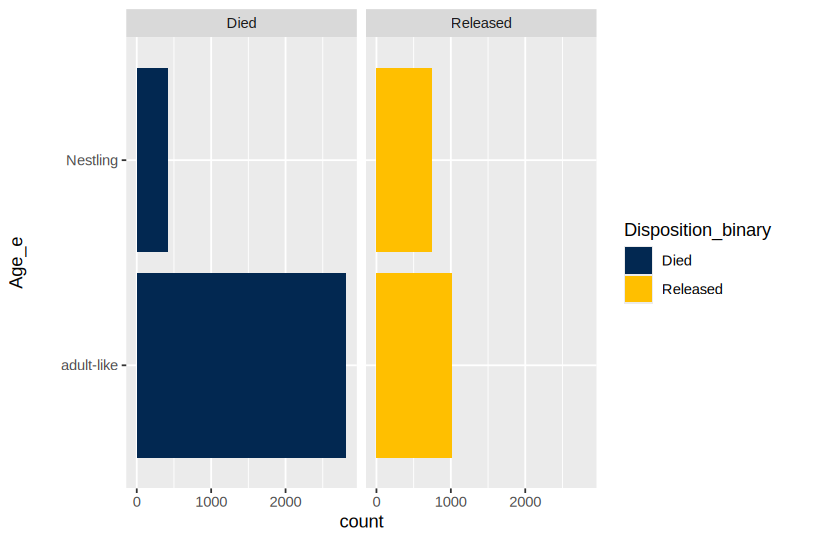

In [ ]:
ggplot(df, aes(x = Age_e, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

**Q11 (4 pts).** What do your tables and plots suggest? Which variables look associated with the outcome? Which **statistical test** could check whether the association is more than chance?

✍️ **Your answer:**
Recieving first aid analysis shows that there's not strong association with survival. However, age analyis shows strong association with survival. Nestlings are more likely to get released compare to adults. We can use odds ratio to check the association.

### 📊 From counts to proportions
**Q12 (5 pts).** Calculate the proportion of birds **released vs. died** at each center, show the table, and plot it as side-by-side bars.

Place,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Lindsey,Died,2712,0.6538091
Lindsey,Released,1436,0.3461909
Santa Barbara,Died,39,0.5342466
Santa Barbara,Released,34,0.4657534
malibu,Died,480,0.6161746
malibu,Released,299,0.3838254


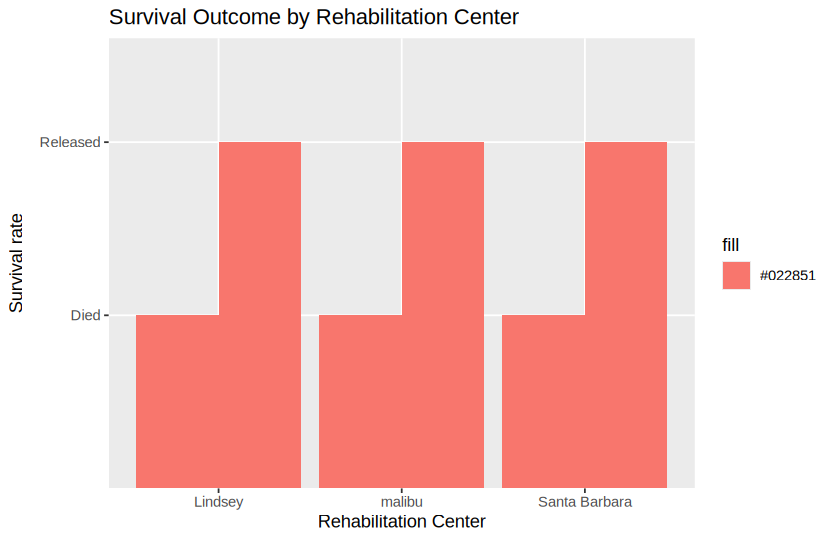

In [ ]:
proportions <- model_data %>%
  group_by(Place, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop") %>%
  group_by(Place) %>%
  mutate(proportion = count / sum(count))
proportions

ggplot(proportions, aes(x = Place, y = Disposition_binary, fill = "#022851")) +
  geom_col(position = "dodge") +
  xlab("Rehabilitation Center") +
  ylab("Survival rate") +
  labs(title = "Survival Outcome by Rehabilitation Center")

## 🧬 Case file 4 · Green birds vs. orange birds

**Q13 (5 pts).** Make a new column `Species_group` with two groups:
* **`Selasphorus`**: all *Selasphorus* birds
* **`Non-selasphorus`**: Anna's (ANHU), Black-chinned (BCHU) and unidentified non-*Selasphorus* birds

Then tabulate and plot survival by `Species_group`. **Do survival proportions differ between the groups?**

✅ *Check yourself:* the dataset already has a `Green_Orange` column. If your grouping is right, `table(model_data$Species_group, model_data$Green_Orange)` has zeros off the diagonal.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

There is only **one** value that belongs in the `Selasphorus` group, so a single `ifelse()` does it: *if* `Species_e` is `"Selasphorus"`, then `"Selasphorus"`, *else* `"Non-selasphorus"`.

</details>

In [ ]:
model_data$Species_group <- ifelse(model_data$Species_e == "Selasphorus", "Selasphorus", "Non-selasphorus")

In [ ]:
table(model_data$Species_group, model_data$Green_Orange)   # self-check



                 
                  Non-selasphorus spp. Selasphorus spp.
  Non-selasphorus                 4136                0
  Selasphorus                        0              864

In [ ]:
species_distribution <- model_data %>%
  group_by(Species_group, Disposition_binary) %>%
  summarise(n=n(), .groups = "drop")

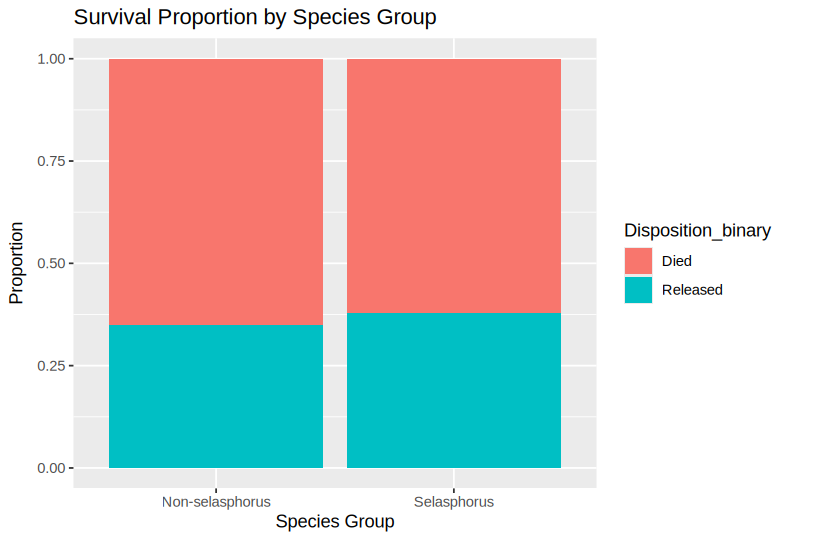

In [ ]:

ggplot(species_distribution, aes(x = Species_group, y = n, fill = Disposition_binary)) +
  geom_col(position = "fill") +
  xlab("Species Group") +
  ylab("Proportion") +
  labs(title = "Survival Proportion by Species Group")

✍️ **Your answer:**
* Survival proportion is simillar between two groups but Selasphorus has slightly highter survival rate.

## ⏳ Case file 5 · Time traveller: admissions over the years

**Q14 (2 pts).** Convert `Admitted` to a real date. Then explain what the `format` argument does, and what would happen if you used `"%d/%m/%Y"` instead.

In [ ]:
model_data$Admitted_date <- as.Date(model_data$Admitted, format = "%m/%d/%Y")
class(model_data$Admitted_date)
range(model_data$Admitted_date)

[1] "Date"

[1] "1991-01-02" "2016-12-21"

In [ ]:
model_data$Admitted_date <- as.Date(model_data$Admitted, format = "%d/%m/%Y")
class(model_data$Admitted_date)
range(model_data$Admitted_date)

[1] "Date"

[1] NA NA

✍️ **Your answer:**
* Format argument tells R to find eact matched data that we enter as that format. In this case "month, day, and year" format. This is why we don't get any data if we put format as "day, month, and year."

**Q15 (4 pts).** 🔮 *Predict first:* which **season** do you think brings the most hummingbirds into care? `Spring` Why? **As it is the time that hummingbirds are migrating.**

Now count admissions per **month** and per **year**, and plot both timelines. Was your season prediction right? (`table(model_data$season)` will tell you.)

In [ ]:
admissions_by_month <- model_data %>%
  mutate(Admitted_month = format(Admitted_date, "%Y-%m")) %>%
  group_by(Admitted_month) %>%
  summarise(count = n(), .groups = "drop")


In [ ]:
admissions_by_year <- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y")) %>%
  group_by(Admitted_year) %>%
  summarise(count = n(), .groups = "drop")

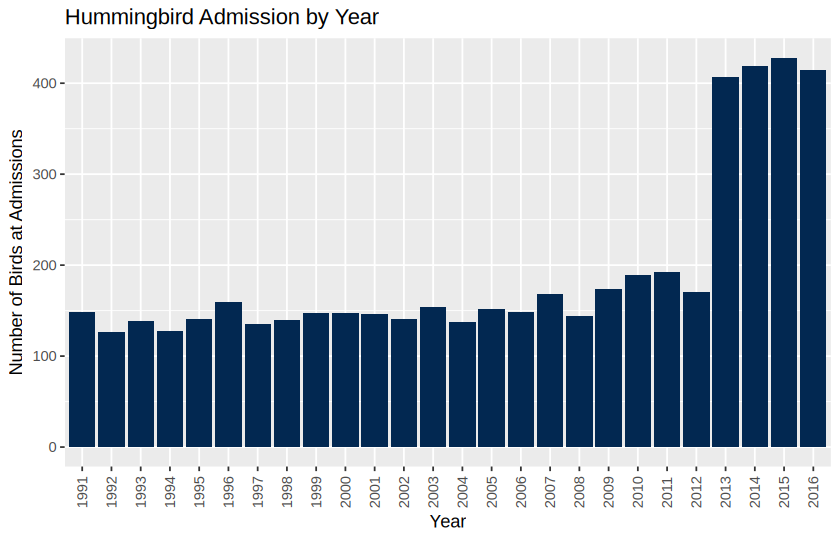

In [ ]:
ggplot(admissions_by_year, aes(x = Admitted_year, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Year") +
  ylab("Number of Birds at Admissions") +
  labs(title = "Hummingbird Admission by Year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

## now plot admissions_by_month the same way

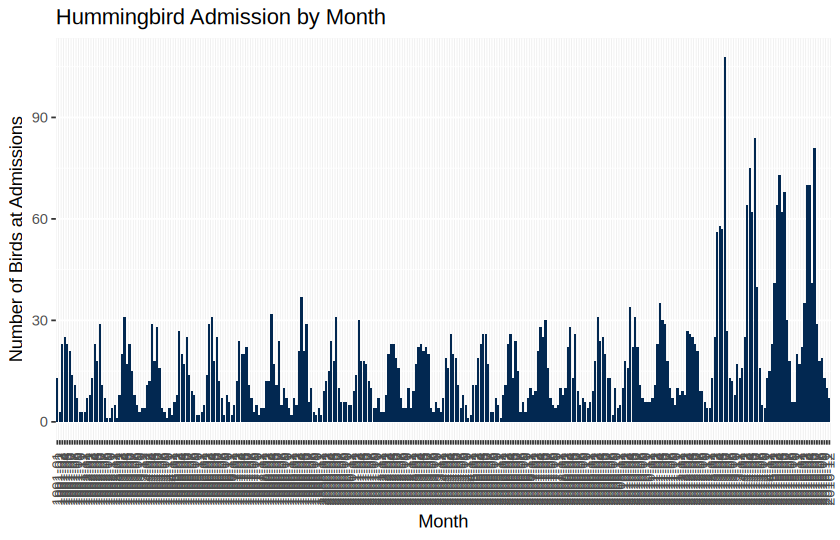

In [ ]:
ggplot(admissions_by_month, aes(x = Admitted_month, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Month") +
  ylab("Number of Birds at Admissions") +
  labs(title = "Hummingbird Admission by Month") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

In [ ]:
table(model_data$season)


  Fall Spring Summer Winter 
   455   2252   1545    748 

**Q16 (2 pts).** 🕵️ **Plot twist.** Admissions roughly **triple** from 2013 onwards. Did hummingbirds suddenly get into three times more trouble? Find out what really changed.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Count admissions by year **and** `Place`: `model_data %>% count(Admitted_year = format(Admitted_date, "%Y"), Place)`. When does each center first appear?

</details>

In [ ]:
# your investigation here
model_data %>% count(Admitted_year = format(Admitted_date, "%Y"), Place)

Admitted_year,Place,n
<chr>,<chr>,<int>
1991,Lindsey,149
1992,Lindsey,127
1993,Lindsey,139
1994,Lindsey,128
1995,Lindsey,141
1996,Lindsey,159
1997,Lindsey,135
1998,Lindsey,140
1999,Lindsey,147


✍️ **Your answer:** Malibu center first appeared in 2012 and Santa Barbara appeared in 2016. As other centers accept the birds, overall number of birds that admitted trippled compared to before.

## 🕵️ Bonus · Data detective (+5 pts)

Real data are messy, and these data have **at least three problems** hiding in the *raw* file (`data`). Find three, show the code that reveals each one, and say how you would fix it **without overwriting the raw file**.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Try `summary(data$Brought_in_after)`, `unique(data$Sex_e)` (look *very* closely at the spaces), and `unique(data$Place)` (look at capitalisation).

</details>

In [ ]:
# your detective work here
summary(data$Brought_in_after)

     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
 -365.000     0.000     0.000     3.058     1.000 16588.000 

In [ ]:
unique(data$Sex_e)

[1] "Female-like " "unknown"      "Male"

In [ ]:
unique(data$Place)

[1] "Lindsey"       "malibu"        "Santa Barbara"

✍️ **Your answer:**
* Brought_in_after: minimum value is minus, which doesn't make sense.
* Sex_e: 'Female-like ' has extra spaces.
* Place: 'malibu' is not capitalized same as other centers.

## 💭 Debrief (2 pts)

**Q17.** In two or three sentences: (a) one thing in this data that surprised you, and (b) one R error you hit and how you fixed it.

✍️ **Your answer:**
I was surprised the number of data that entered wrong (Brought_in_after) that cause negative days and contribute to the minimum values.

When I was coding, I mistyped '$' to '&' when we choose data and variable to worwith and was unable to code. So I compare to other code that I used above that fix back to '$.'

## 🎨 Hall of Fame (optional, not graded)
Make your **most beautiful** plot from this dataset, in Aggie Blue `#022851` and Aggie Gold `#FFBF00`. The best ones get shown in class. 🏆

## 📤 How to submit
1. Run every cell from the top (**Runtime → Restart and run all**) so the outputs are fresh.
2. Save the notebook to **your branch** of the course GitHub repo: File → Save a copy in GitHub (**never `main`**).
3. Download and submit `Hummingbird_data_YOURNAME.csv` and `rehab_counts_YOURNAME.pdf` from `outputs/`.

In [ ]:
beep_colab("smb_stage_clear")   # mission complete 🍄